In [129]:
import pandas as pd
import scripts.visualisation as vis
import scripts.calculations as calc
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
import matplotlib.pyplot as plt

In [ ]:
import importlib
importlib.reload()

<module 'scripts.visualisation' from '/Users/hounczy/Library/CloudStorage/OneDrive-ITU/3. Semester/Machine Learning/Project/scripts/visualisation.py'>

In [65]:
df = pd.read_csv("data/case1/train1.csv")
df.head()

,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,flow_m3_h
0,99223468_model_01,14.5,stable,4230.396017,669.992714,1.057136,2.414427,0.652884
1,99223468_model_01,24.5,stable,3796.519900,931.528480,2.097392,2.390436,43.040564
2,99223468_model_01,34.5,stable,3508.264375,724.198083,2.247896,2.433662,40.939560
3,99223468_model_01,44.5,stable,1498.405243,99.463217,2.287246,2.451128,11.857951
4,99223468_model_01,64.5,stable,3224.873653,608.195308,2.464618,2.696299,36.000996


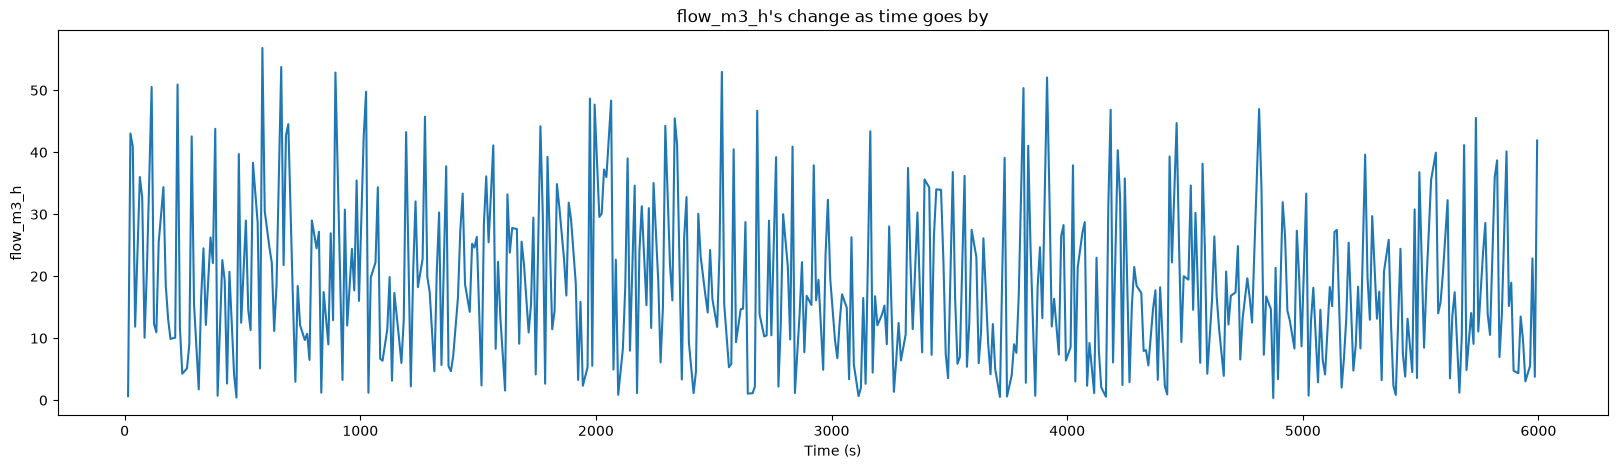

In [66]:
vis.plotFeature_byTime(df, "flow_m3_h")

---

In [67]:
df.head()

,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,flow_m3_h
0,99223468_model_01,14.5,stable,4230.396017,669.992714,1.057136,2.414427,0.652884
1,99223468_model_01,24.5,stable,3796.519900,931.528480,2.097392,2.390436,43.040564
2,99223468_model_01,34.5,stable,3508.264375,724.198083,2.247896,2.433662,40.939560
3,99223468_model_01,44.5,stable,1498.405243,99.463217,2.287246,2.451128,11.857951
4,99223468_model_01,64.5,stable,3224.873653,608.195308,2.464618,2.696299,36.000996


In [68]:
# Task 0
n = df["speed_rpm"] / 1000
Q = df["flow_m3_h"]
y = df["power_w"]

X = pd.DataFrame(index=df.index)
for i in range(4):
    for j in range(4):
        if i == 0 and j == 0:
            continue # intercept
        X[f"n{i}_Q{j}"] = (n**i)*(Q**j)

In [69]:
X.head()

,n0_Q1,n0_Q2,n0_Q3,n1_Q0,n1_Q1,n1_Q2,n1_Q3,n2_Q0,n2_Q1,n2_Q2,n2_Q3,n3_Q0,n3_Q1,n3_Q2,n3_Q3
0,0.652884,0.426257,0.278296,4.230396,2.761956,1.803236,1.177303,17.896250,11.684169,7.628402,4.980459e+00,75.708227,49.428660,32.271162,2.106931e+01
1,43.040564,1852.490174,79732.222413,3.796520,163.404359,7033.015810,302704.969059,14.413563,620.367900,26700.984478,1.149225e+06,54.721380,2355.239078,101370.818919,4.363057e+06
2,40.939560,1676.047551,68616.648822,3.508264,143.626799,5880.017914,240725.344589,12.307919,503.880782,20628.657370,8.445282e+05,43.179433,1767.746997,72370.783753,2.962828e+06
3,11.857951,140.610999,1667.358317,1.498405,17.768016,210.692258,2498.378443,2.245218,26.623688,315.702384,3.743583e+03,3.364247,39.893074,473.050107,5.609405e+03
4,36.000996,1296.071689,46659.871276,3.224874,116.098662,4179.667444,150472.189541,10.399810,374.403518,13478.899418,4.852538e+05,33.538074,1207.404040,43467.747606,1.564882e+06


In [70]:
model = LinearRegression()
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[-0.08,-0.77, 0.01,..., 0.16, 0.02,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['n0_Q1','n0_Q2','n0_Q3',...,'n3_Q1','n3_Q2','n3_Q3']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,41.72
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [71]:
coefficients = pd.Series(model.coef_, index=X.columns)

print("Intercept:", model.intercept_)
print(coefficients)

Intercept: 41.71503904233782
n0_Q1   -0.078093
n0_Q2   -0.774463
n0_Q3    0.011267
n1_Q0    0.315945
n1_Q1    0.540768
n1_Q2    0.696292
n1_Q3   -0.019278
n2_Q0    1.686435
n2_Q1    1.586615
n2_Q2   -0.197088
n2_Q3    0.005497
n3_Q0    7.230393
n3_Q1    0.162069
n3_Q2    0.015206
n3_Q3   -0.000482
dtype: float64


In [103]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def validation_rmse(features):
    scores = cross_val_score(
        LinearRegression(),
        X[features],
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    return -scores.mean()

In [104]:
all_features = list(X.columns)

full_rmse = validation_rmse(all_features)
print(f"Full model validation RMSE: {full_rmse:.3f}")

Full model validation RMSE: 11.045


In [74]:
selected_features = all_features.copy()

results = [{
    "n_features": len(selected_features),
    "rmse": full_rmse,
    "features": selected_features.copy()
}]

while len(selected_features) > 1:
    candidates = []

    for feature in selected_features:
        remaining = [
            column for column in selected_features
            if column != feature
        ]

        candidates.append({
            "n_features": len(remaining),
            "rmse": validation_rmse(remaining),
            "features": remaining
        })

    best_candidate = min(candidates, key=lambda result: result["rmse"])

    selected_features = best_candidate["features"].copy()
    results.append(best_candidate)

results_df = pd.DataFrame(results)

print(results_df[["n_features", "rmse"]].to_string(index=False))

 n_features       rmse
         15  11.045051
         14  10.510598
         13  10.483386
         12  10.473440
         11  10.472899
         10  10.472684
          9  10.482511
          8  10.471198
          7  10.463790
          6  10.504365
          5  10.469175
          4  10.398158
          3  11.478028
          2 115.882288
          1 178.688061


In [76]:
best_result = min(results, key=lambda result: result["rmse"])
best_features = best_result["features"]

print("Selected features:", best_features)
print(f"Validation RMSE: {best_result['rmse']:.3f}")

Selected features: ['n0_Q3', 'n1_Q2', 'n2_Q1', 'n3_Q0']
Validation RMSE: 10.398


In [77]:
best_result

{'n_features': 4,
 'rmse': np.float64(10.398158204884728),
 'features': ['n0_Q3', 'n1_Q2', 'n2_Q1', 'n3_Q0']}

In [78]:
final_model = LinearRegression()
final_model.fit(X[best_features], y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.01,-0.05, 2.41, 7.66]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['n0_Q3','n1_Q2','n2_Q1','n3_Q0']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,40.86
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


---

In [79]:
df.head()

,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,flow_m3_h
0,99223468_model_01,14.5,stable,4230.396017,669.992714,1.057136,2.414427,0.652884
1,99223468_model_01,24.5,stable,3796.519900,931.528480,2.097392,2.390436,43.040564
2,99223468_model_01,34.5,stable,3508.264375,724.198083,2.247896,2.433662,40.939560
3,99223468_model_01,44.5,stable,1498.405243,99.463217,2.287246,2.451128,11.857951
4,99223468_model_01,64.5,stable,3224.873653,608.195308,2.464618,2.696299,36.000996


In [113]:
n1 = df["speed_rpm"] / 1000
P = df["power_w"]
delta_p = df["outlet_pressure_bar"]-df["inlet_pressure_bar"]
y1 = df["flow_m3_h"]

X1 = pd.DataFrame()
X1["speed_krpm"] = n1
X1["power_w"] = P 
X1["delta_p"] = delta_p

In [114]:
model1 = LinearRegression()
model1.fit(X1,y1)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 8.95, 0.02,-36.29]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['speed_krpm','power_w','delta_p']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.4631
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [ ]:
cv1 = KFold(n_splits=5, shuffle=True, random_state=42)
all_features1 = list(X1.columns)

In [139]:
importlib.reload(calc)

<module 'scripts.calculations' from '/Users/hounczy/Library/CloudStorage/OneDrive-ITU/3. Semester/Machine Learning/Project/scripts/calculations.py'>

In [128]:
calc.calc_rmse(model1,cv1, X1, all_features1,y1)

np.float64(3.48)

In [140]:
calc.feature_selection(X1,model1,cv1,all_features1,y1)

                    features  rmse
speed_krpm, power_w, delta_p 3.480
            power_w, delta_p 4.468
                     power_w 9.994


In [141]:
calc.feature_selection(X,model,cv,all_features,y)

                                                                                               features    rmse
n0_Q1, n0_Q2, n0_Q3, n1_Q0, n1_Q1, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q2, n2_Q3, n3_Q0, n3_Q1, n3_Q2, n3_Q3  11.045
       n0_Q1, n0_Q3, n1_Q0, n1_Q1, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q2, n2_Q3, n3_Q0, n3_Q1, n3_Q2, n3_Q3  10.511
              n0_Q1, n0_Q3, n1_Q0, n1_Q1, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q2, n2_Q3, n3_Q0, n3_Q1, n3_Q3  10.483
                     n0_Q1, n0_Q3, n1_Q0, n1_Q1, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q3, n3_Q0, n3_Q1, n3_Q3  10.473
                            n0_Q3, n1_Q0, n1_Q1, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q3, n3_Q0, n3_Q1, n3_Q3  10.473
                                   n0_Q3, n1_Q1, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q3, n3_Q0, n3_Q1, n3_Q3  10.473
                                          n0_Q3, n1_Q2, n1_Q3, n2_Q0, n2_Q1, n2_Q3, n3_Q0, n3_Q1, n3_Q3  10.483
                                                 n0_Q3, n1_Q2, n1_Q3, n2_Q1, n2_Q3, n3_Q0, n3_Q1, n3_Q3 

---